# 实验五：基于LeNet的手写数字识别
补全两次卷积、平均池化和三层全连接网络，按参考参数训练MNIST共30轮。

In [1]:
import torch
import torchvision
from lenet_model import Net
from IPython.display import Image, display
print("PyTorch:", torch.__version__, "torchvision:", torchvision.__version__)
print(Net())

PyTorch: 2.15.0 torchvision: 0.29.2
Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (clf): Linear(in_features=84, out_features=10, bias=True)
)


## 训练与评估
训练集60000张、测试集10000张，batch_size=512，Adam学习率0.01。

In [2]:
%run lenet.py

Matplotlib is building the font cache; this may take a moment.


Python 3.12.14 | PyTorch 2.15.0 | torchvision 0.29.2


Device: cpu | Seed: 42 | Batch size: 512 | Adam lr: 0.01 | Epochs: 30


MNIST train: 60000 | test: 10000 | input: 1x28x28


Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (clf): Linear(in_features=84, out_features=10, bias=True)
)


Parameters: 61706


... (28 outputs left out)

epoch:28, loss:0.0512, acc:0.9861


epoch:29, loss:0.0488, acc:0.9864


Final: 9864/10000 | Accuracy: 98.64%


Training/evaluation time: 165.72s | Saved results, feature maps and model_final.pt


## 损失与准确率

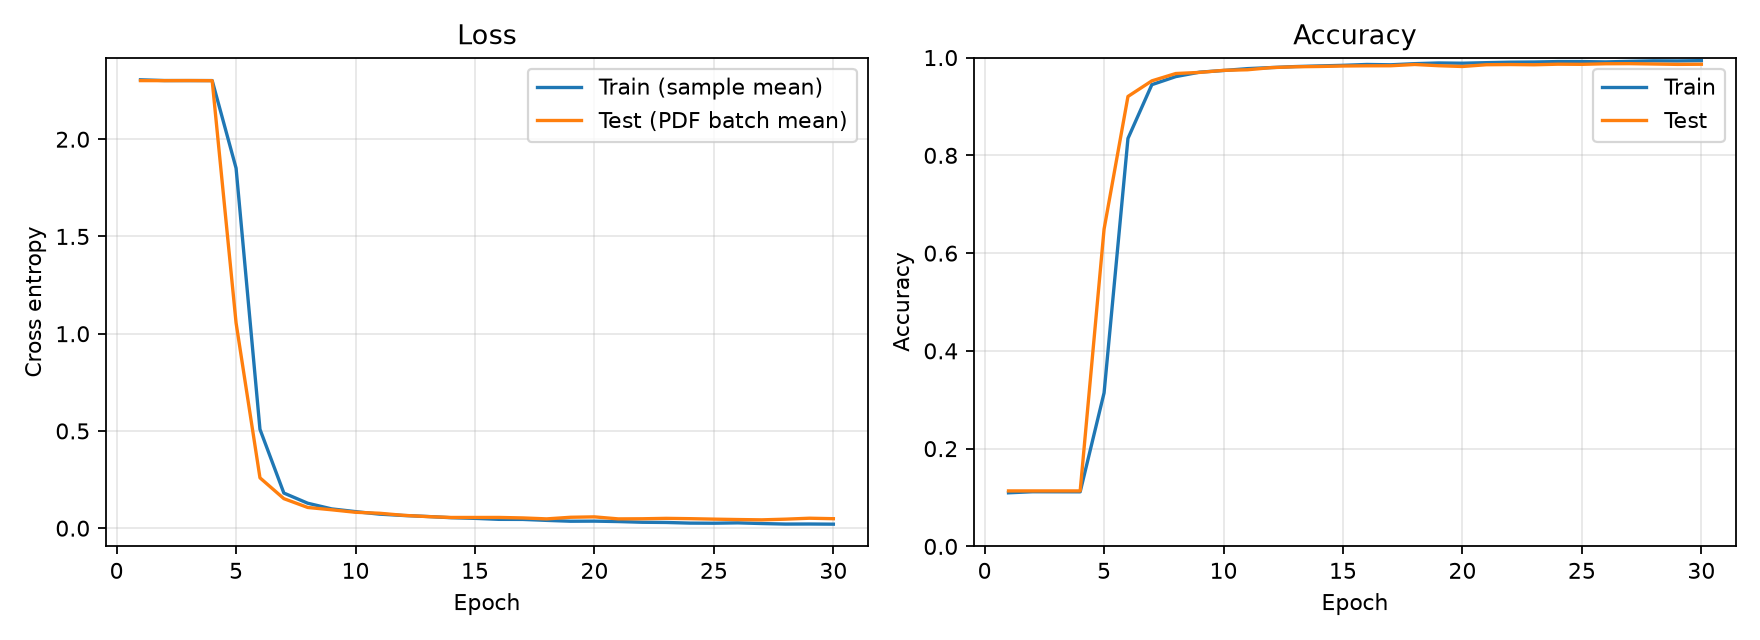

In [3]:
display(Image(filename="results/02_learning_curves.png", width=1050))

## 前20张测试图像的识别结果

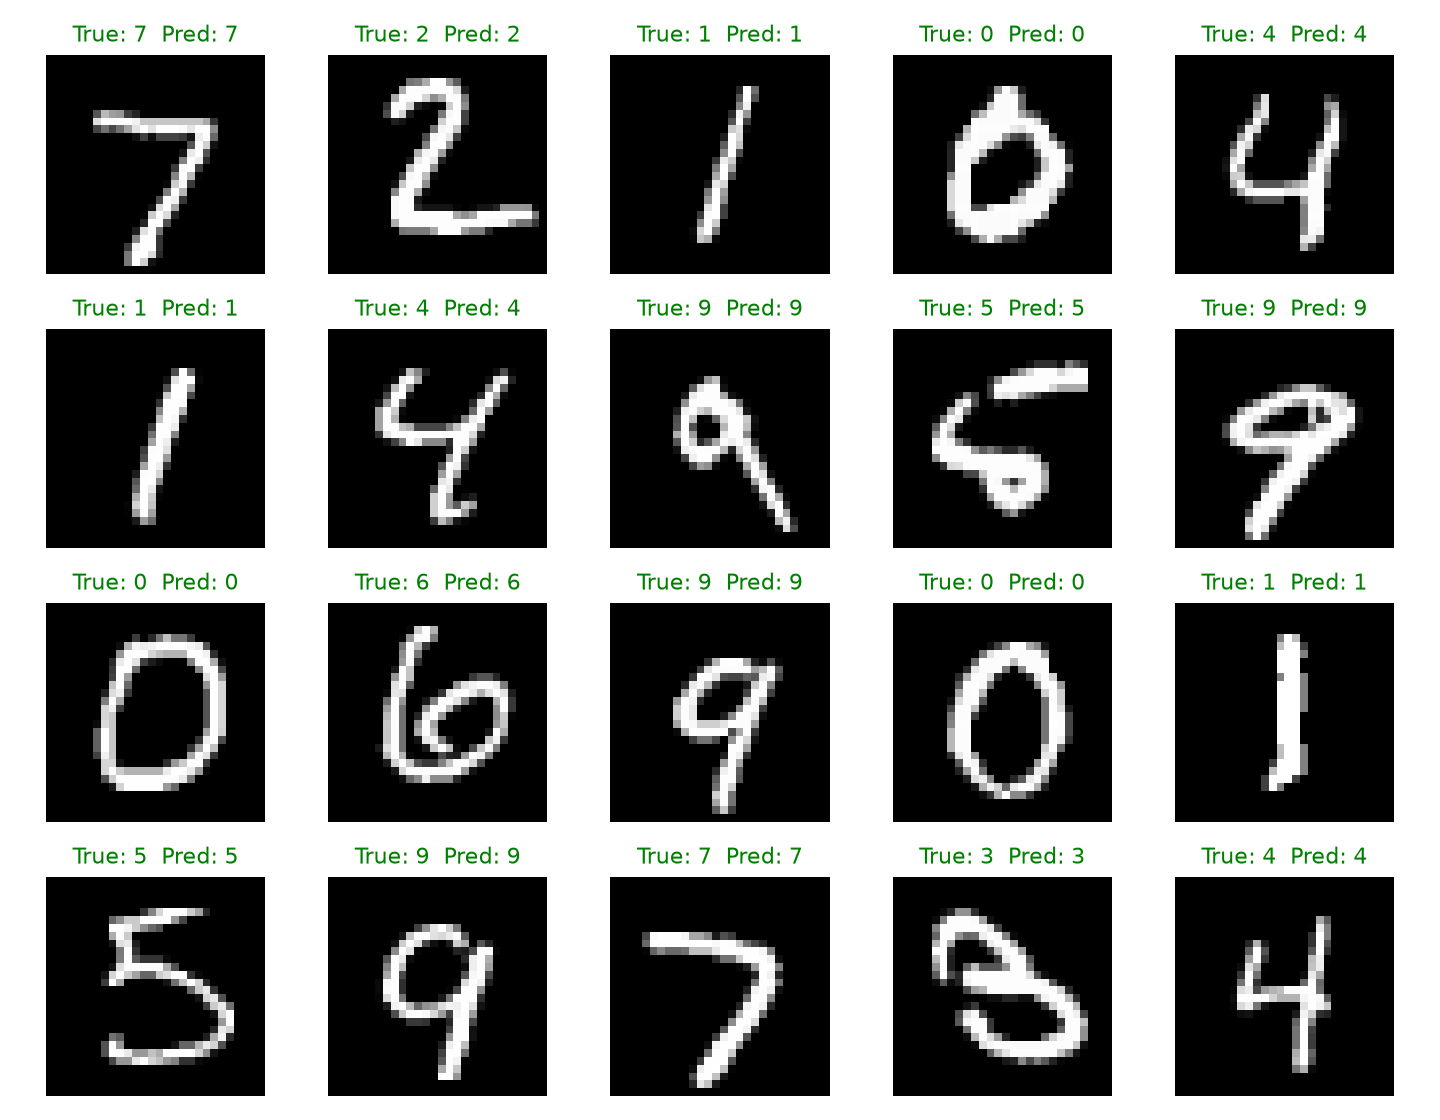

In [4]:
display(Image(filename="results/03_predictions.png", width=850))

## 测试集混淆矩阵

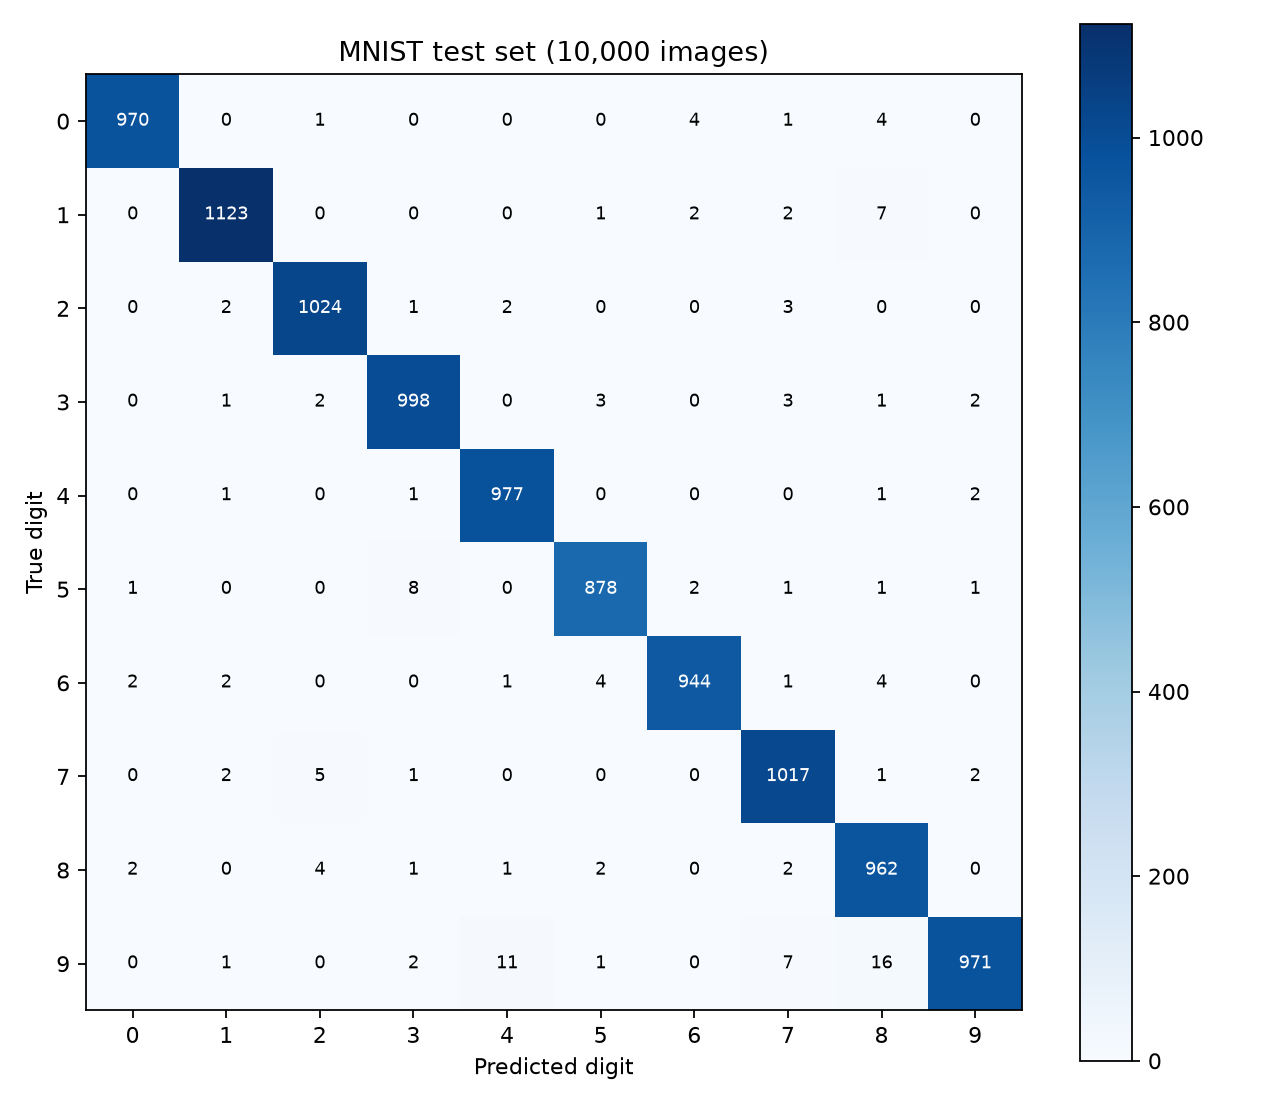

In [5]:
display(Image(filename="results/04_confusion_matrix.png", width=800))

## 卷积特征图
按参考代码取最后一个测试批次的前5张，三行依次为输入、第一层卷积激活通道和、第二层卷积激活通道和。

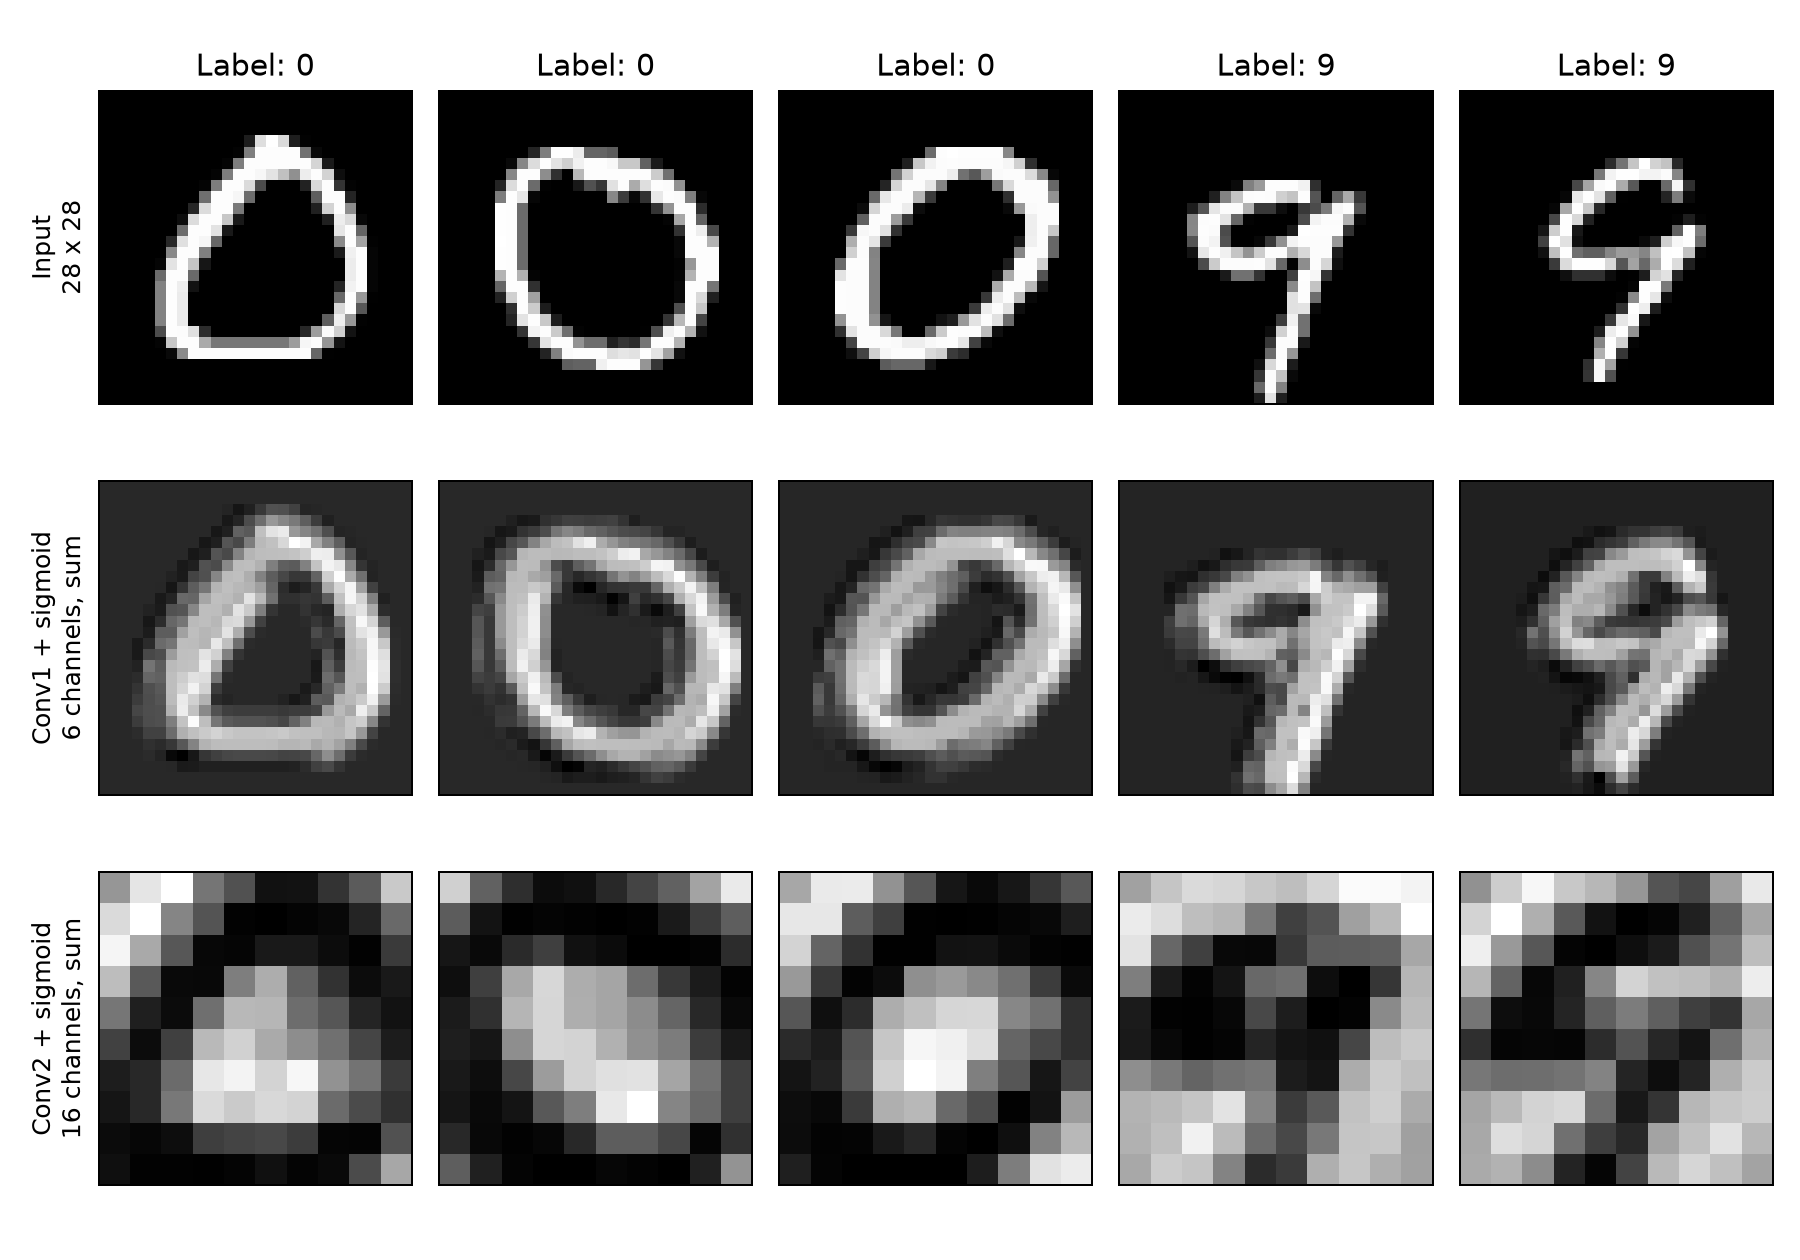

In [6]:
display(Image(filename="results/05_feature_maps.png", width=1000))

## 追加两组数据测试
使用第30轮模型，依次选测试集索引20–39、40–59，每组20张。

In [1]:
%run additional_tests.py

Model: epoch 29 | Device: cpu
Group 1 | test indices 20-39 | Correct: 20/20 | Accuracy: 100.00%
Labels:      [9, 6, 6, 5, 4, 0, 7, 4, 0, 1, 3, 1, 3, 4, 7, 2, 7, 1, 2, 1]
Predictions: [9, 6, 6, 5, 4, 0, 7, 4, 0, 1, 3, 1, 3, 4, 7, 2, 7, 1, 2, 1]
Group 2 | test indices 40-59 | Correct: 20/20 | Accuracy: 100.00%
Labels:      [1, 7, 4, 2, 3, 5, 1, 2, 4, 4, 6, 3, 5, 5, 6, 0, 4, 1, 9, 5]
Predictions: [1, 7, 4, 2, 3, 5, 1, 2, 4, 4, 6, 3, 5, 5, 6, 0, 4, 1, 9, 5]


### 第一组：测试集第21–40张

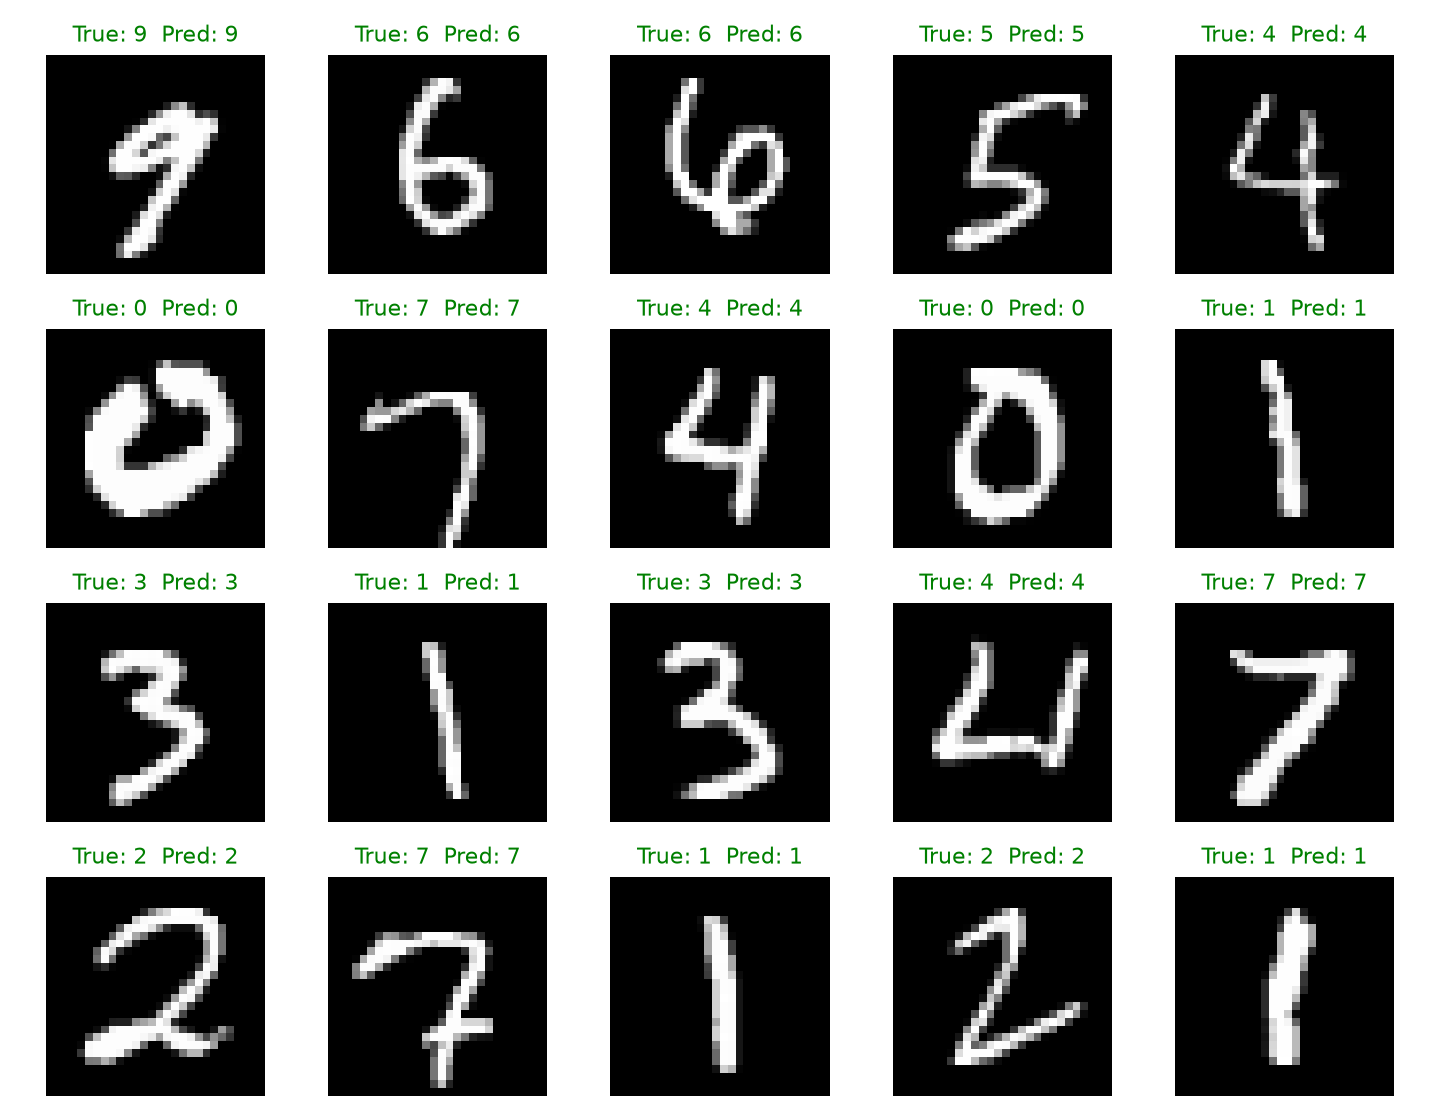

In [2]:
from IPython.display import Image, display
display(Image(filename="results/06_group1_predictions.png", width=850))

### 第二组：测试集第41–60张

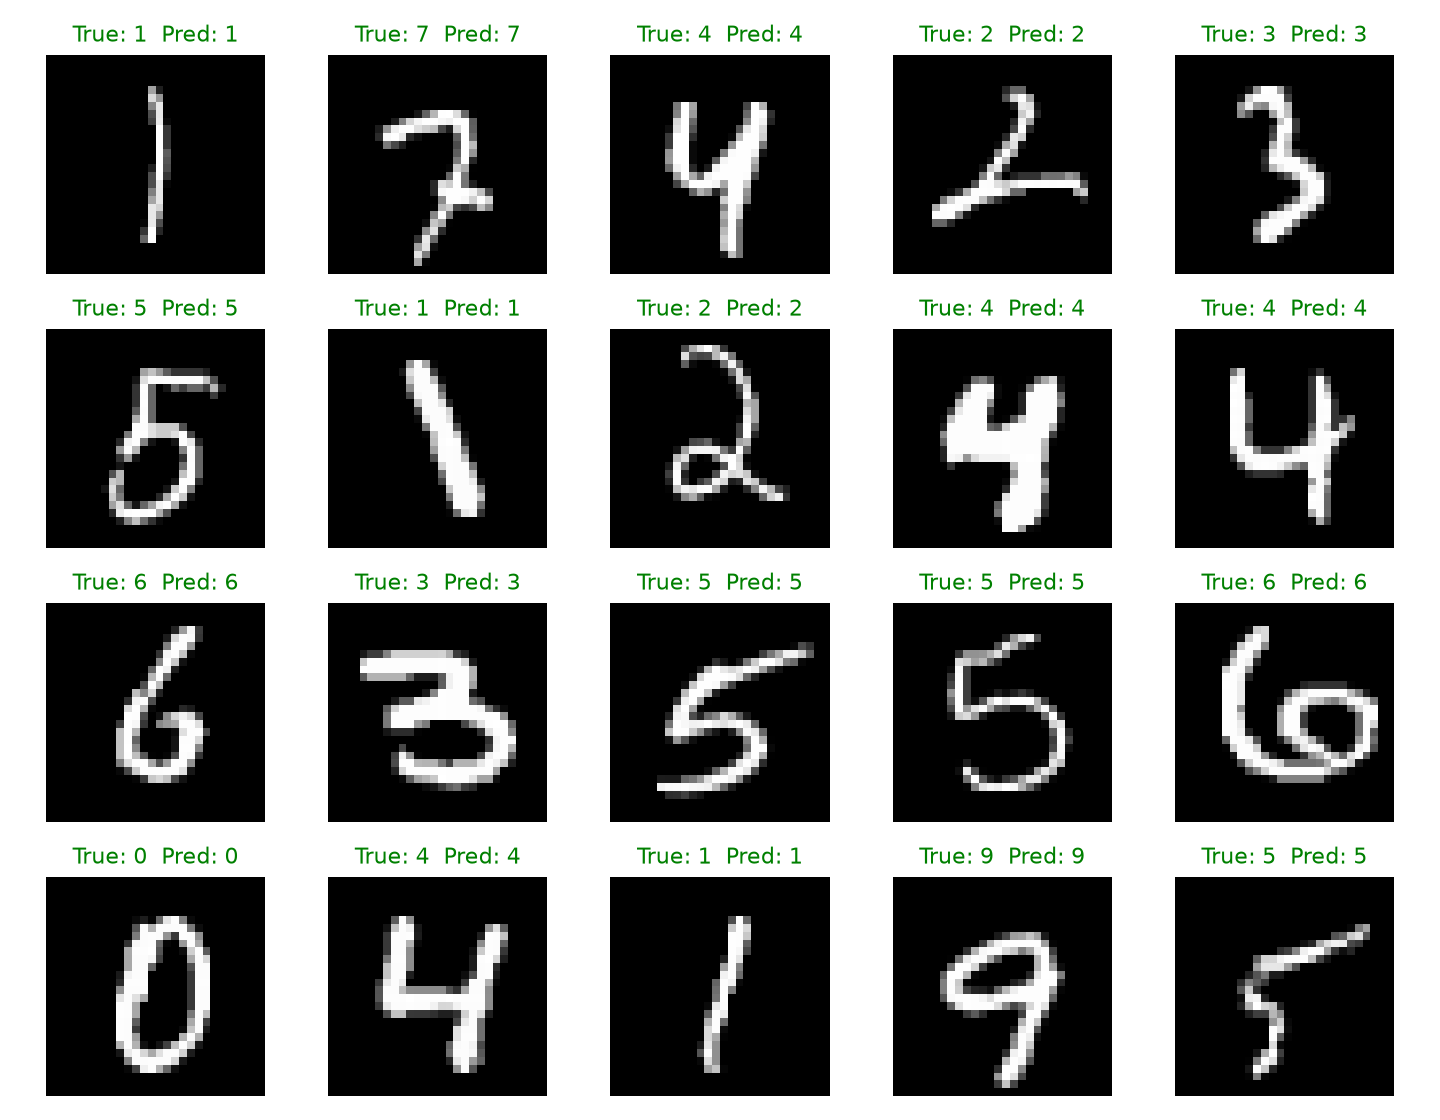

In [3]:
display(Image(filename="results/07_group2_predictions.png", width=850))